# LogP: faithfulness results

In [1]:
from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_DATASETS,
    REAL_WORLD_RESULTS,
    REAL_WORLD_TARGET_COLORS,
    calculate_stats_by_method_target,
    combine_and_calculate_variance,
    compute_correlation_summary,
    compute_k_effect,
    create_grouped_boxplot,
    load_raw_data,
    load_raw_data_all_thres,
    pair_xai_methods,
    plot_boxplot_grid_by_model,
    plot_correlation_heatmap,
    plot_k_effect_bars,
    plot_negative_deviations,
    plot_std_by_method_target,
    process_fidelity_df,
)

In [2]:
DATASET = 'LogP'
FOLDER, TARGET_NAME = REAL_WORLD_DATASETS[DATASET]
BASE_DIR = REAL_WORLD_RESULTS / FOLDER
OUTPUT_DIR = BASE_DIR / 'result_plots'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
fid_df = process_fidelity_df(load_raw_data(BASE_DIR, TARGET_NAME))
fid_all_thres_df = process_fidelity_df(load_raw_data_all_thres(BASE_DIR, TARGET_NAME))
target_data = {DATASET: fid_df}

logp: 241,382 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
206,882 rows | {'faithful': 143196, 'unfaithful': 63686} | normalized_fid in [-1.000, 1.000]


logp: 2,172,438 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


1,861,938 rows | {'faithful': 1249201, 'unfaithful': 612737} | normalized_fid in [-1.000, 1.000]


## Fid+ by xAI method and model

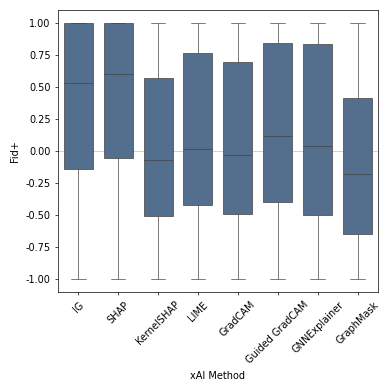

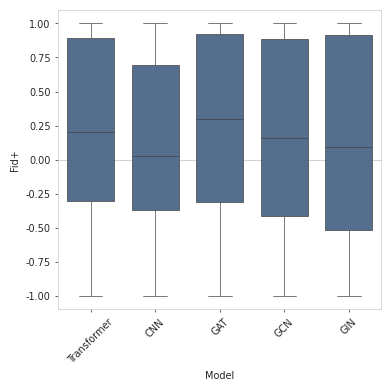

In [4]:
for group_col in ('explanation_method', 'model'):
    create_grouped_boxplot(target_data, value_col='normalized_fid', group_col=group_col, figsize=(4, 4),
                           target_colors=REAL_WORLD_TARGET_COLORS, output_dir=OUTPUT_DIR)

## xAI methods per model

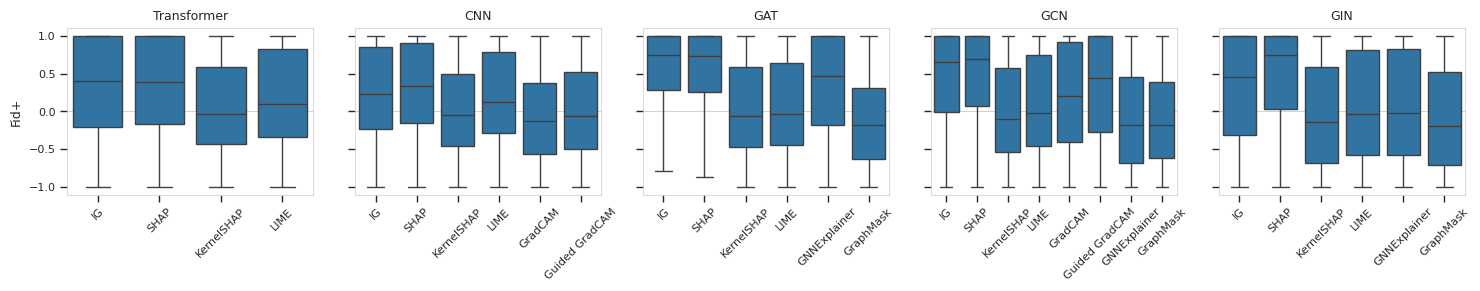

In [5]:
plot_boxplot_grid_by_model(fid_df, output_dir=OUTPUT_DIR);

## Summary table & standard deviation

In [6]:
variance_df = combine_and_calculate_variance(target_data)
variance_df

,model,explanation_method,target,n,mean,median,std,var
25,GIN,SHAP,LogP,6900,0.451,0.749,0.659,0.434
8,GAT,IG,LogP,6900,0.522,0.742,0.581,0.337
11,GAT,SHAP,LogP,6900,0.511,0.732,0.586,0.344
19,GCN,SHAP,LogP,6900,0.450,0.694,0.628,0.395
16,GCN,IG,LogP,6900,0.424,0.659,0.638,0.408
6,GAT,GNNExplainer,LogP,6900,0.305,0.473,0.664,0.441
22,GIN,IG,LogP,6900,0.260,0.449,0.706,0.498
15,GCN,Guided GradCAM,LogP,6782,0.267,0.435,0.693,0.480
26,Transformer,IG,LogP,6900,0.276,0.396,0.669,0.448
29,Transformer,SHAP,LogP,6900,0.279,0.385,0.660,0.436


In [7]:
calculate_stats_by_method_target(target_data)

,explanation_method,target,n,median,std,var
0,GNNExplainer,LogP,20700,0.035669,0.713248,0.508723
1,GradCAM,LogP,13800,-0.034944,0.685797,0.470317
2,GraphMask,LogP,20700,-0.180235,0.673942,0.454198
3,Guided GradCAM,LogP,13682,0.116849,0.689067,0.474813
4,IG,LogP,34500,0.526751,0.659426,0.434842
5,KernelSHAP,LogP,34500,-0.073253,0.669660,0.448444
6,LIME,LogP,34500,0.016418,0.679761,0.462075
7,SHAP,LogP,34500,0.602354,0.640570,0.410330


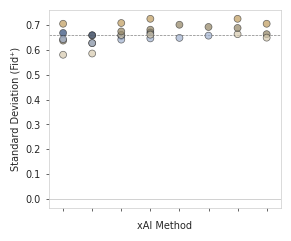

In [8]:
plot_std_by_method_target(variance_df, output_dir=OUTPUT_DIR);

## Parameter k analysis

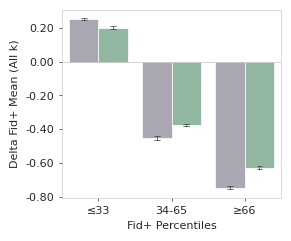

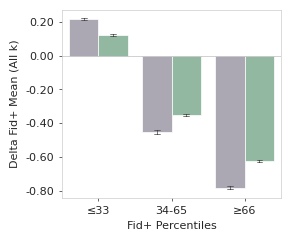

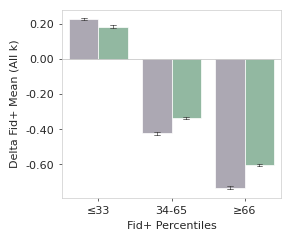

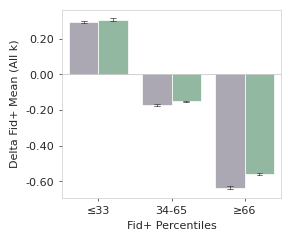

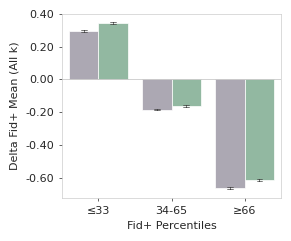

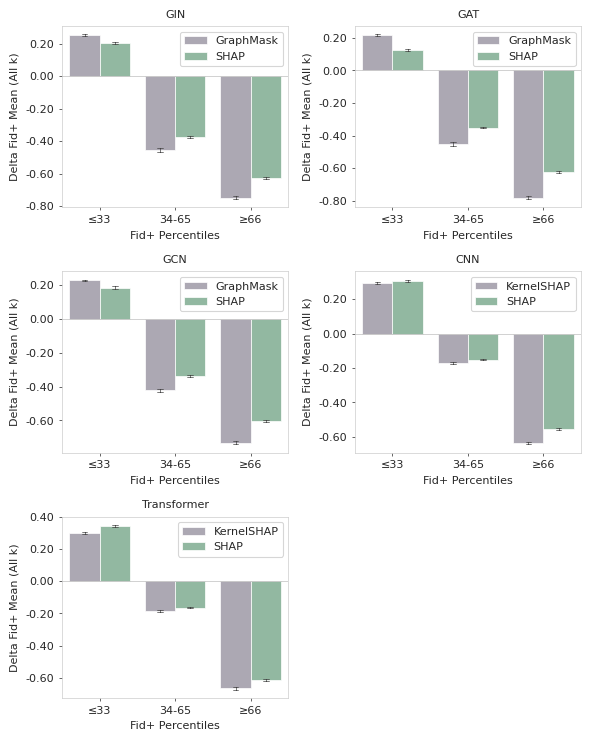

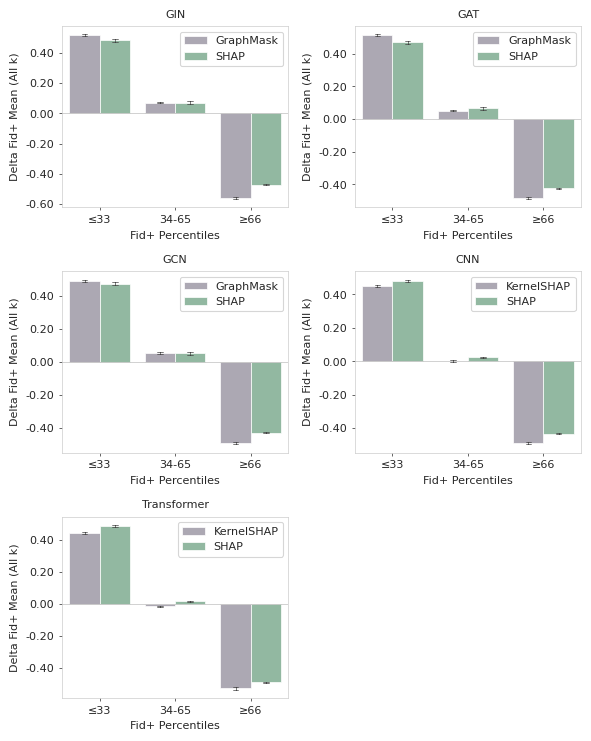

In [9]:
k_effect_df = compute_k_effect(fid_all_thres_df)
plot_k_effect_bars(k_effect_df, OUTPUT_DIR)

### Negative deviation

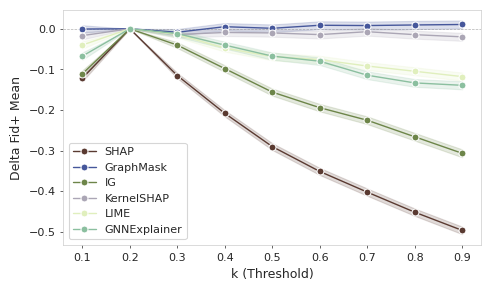

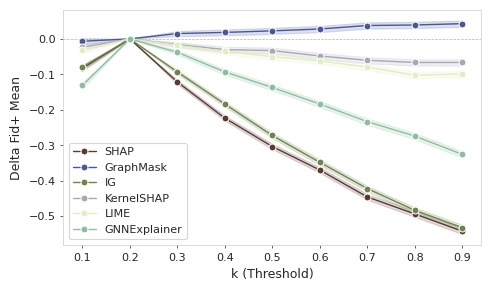

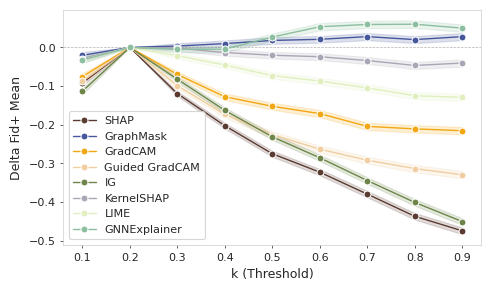

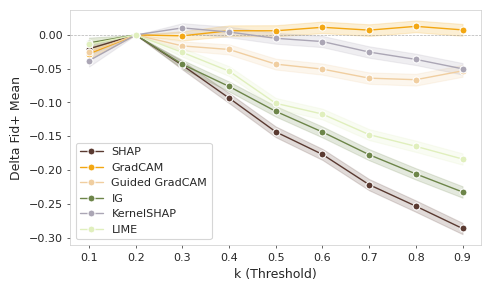

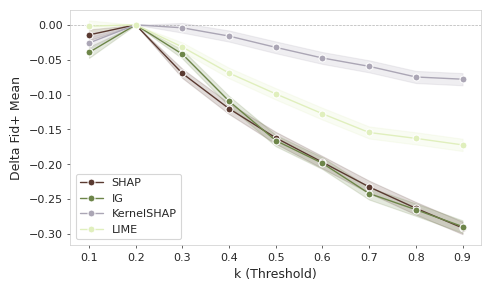

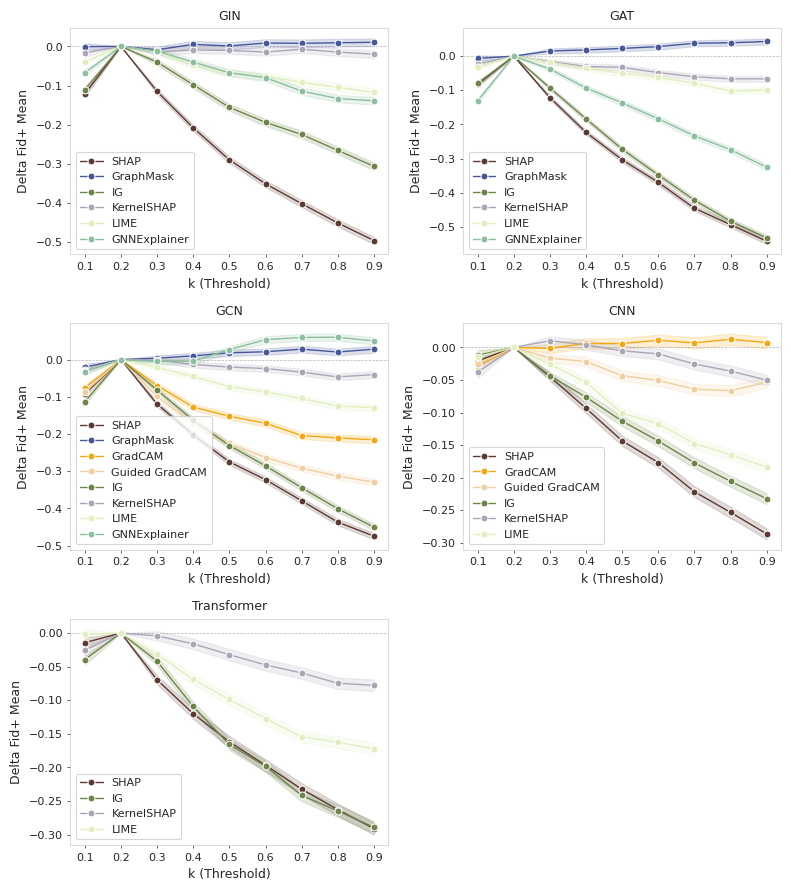

In [10]:
plot_negative_deviations(k_effect_df, OUTPUT_DIR)

## IG vs SHAP agreement

Per-molecule Normalized Fid+ of `integrated_gradients` and `shap_sampling` (same model, smiles, data split) are paired and correlated, to see whether "hard to explain" molecules are intrinsic to the molecule/model or an artifact of the xAI method.

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,LogP,CNN,6900,0.603708,0.0,0.634450,0.0
1,LogP,GAT,6900,0.654376,0.0,0.768469,0.0
2,LogP,GCN,6900,0.605721,0.0,0.694132,0.0
3,LogP,GIN,6900,0.474516,0.0,0.552207,0.0
4,LogP,Transformer,6900,0.697972,0.0,0.736395,0.0


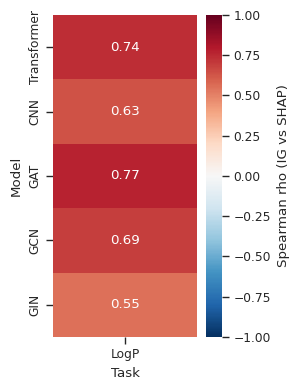

In [12]:
ig_shap_df = pair_xai_methods(fid_df).assign(task=DATASET)
ig_shap_corr_df = compute_correlation_summary(ig_shap_df, ['task', 'model'], 'normalized_fid_ig', 'normalized_fid_shap')
plot_correlation_heatmap(ig_shap_corr_df, output_dir=OUTPUT_DIR)
ig_shap_corr_df

### KernelSHAP vs SHAP agreement

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,LogP,CNN,6900,0.415819,1.027430e-286,0.412588,7.156850e-282
1,LogP,GAT,6900,0.314507,2.962188e-158,0.343817,1.024412e-190
2,LogP,GCN,6900,0.331266,2.238463e-176,0.366627,1.579604e-218
3,LogP,GIN,6900,0.282775,4.981053e-127,0.343836,9.729751e-191
4,LogP,Transformer,6900,0.395261,8.520010e-257,0.397122,2.033526e-259


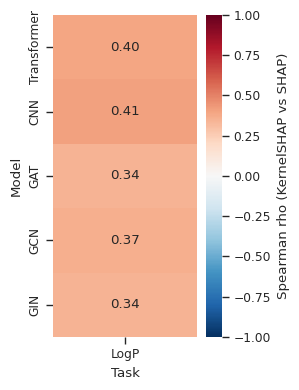

In [13]:
kernel_shap_df = pair_xai_methods(fid_df, method_a='kernel_shap', label_a='kernel_shap').assign(task=DATASET)
kernel_shap_corr_df = compute_correlation_summary(
    kernel_shap_df, ['task', 'model'], 'normalized_fid_kernel_shap', 'normalized_fid_shap'
)
plot_correlation_heatmap(kernel_shap_corr_df, cbar_label='Spearman rho (KernelSHAP vs SHAP)', output_dir=OUTPUT_DIR,
                         filename='kernel_shap_vs_shap_correlation_heatmap')
kernel_shap_corr_df

## Model comparison

In [ ]:
# comparison_csv = BASE_DIR / 'multi_model_comparison.csv'
# format_multi_model_comparison_table(comparison_csv)

In [ ]:
# print(format_latex_model_comparison_table(
#     comparison_csv,
#     caption='Model performance for the LogP task.',
#     label='tab:model_perf_logp',
# ))